## Generate ga data

\

----- todo -----

kurtosis is high for nodes nearby fundamental due to edge effects

--- completed ---

fixed issues with incompatibility with new metrics code

fixed frequency thresholding (see def _dwpt())

added ability to choose which statistical features to calculate instead of calculating them all

added dwt and inv_node tests

minimum energy has the effect of preventing nodes around the fundamental from decomposing too far

energy condition finds fundamental but can split too far. maximum level stops this from going too far

kurtosis threshold works for higher kurtosis signals

max level: frequency / 4 for pcd data, frequency / 2 for ga data (kmeans paper)

--- future work ---

tree plot could plot metrics or reconstructed signals or something

tree plot could show which rule(s) was used to split the node

make inv_plot_tree

find alternative decompositions

clustering plot should show metrics on hover

In [1]:
import sys
sys.path.append("..")
if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

import scipy.ndimage as ndi
import plotly.graph_objects as go
import numpy as np

In [2]:
from wavelet_transform.wpt import transform as wpt
import wavelet_transform.utils.bubble_data_manager as bdm
from wavelet_transform.utils.preprocessing import preprocess, add_noise, len_full_cycles
from wavelet_transform.utils.extensions import to_dB, psd, trim_data
import wavelet_transform.wpt.inverse_transform as inv
from wavelet_transform.utils.machine_learning import fit_k_means
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.postprocess.plotting import relabel
import wavelet_transform.utils.statistical_features as sf
import wavelet_transform.utils.PCD_data as pcd
import wavelet_transform.utils.kmeans_results as results
from wavelet_transform.utils.save_plots import save_figure

In [3]:
use_bd = False  # whether to use the B&D model to generate data
savefigs_flag = False
savedata_flag = False

### Get experimental data

In [4]:
data_trim = None  # data is not trimmed by default

In [5]:
if use_bd is False:
    frequency = 1.1 * 1e6
    pcd_number = 1
    voltage = 80  # 80 or 280
    data, t_plot = pcd.get_data((voltage, pcd_number))  # [80, 120, 200, 280], [1, 5, 10]

    # # Trim data to periodic section
    t_lims = (0e-6, 100e-6)
    data_trim, t_plot = trim_data(data, t_plot, t_lims, return_time=True)

    sampling_rate = np.average(np.diff(t_plot))**-1
    print(f"Sampling rate: {sampling_rate/1e6:.2f} MHz")

    result_id = f"{voltage}_{pcd_number}"

imported data from file: ../data/PCD data for paper/Test2_HIFU_NoVial_80mVpp_Modf.mat
Sampling rate: 200.00 MHz


### Bubble Dynamics Parameters

In [6]:
if use_bd:
    # Set the sonication pulse parameters
    pac = 1e6  # the amplitude of the sine wave in Pa
    frequency = 1.1 * 1e6  # insonation frequency (Hz)
    period = 1 / frequency  # the period of the acoustic wave at the fundamental frequency 
    n_cycles = 100  # no. of cycles of the sine wave
    parameters = {
        "time_delay": 0 * period,  # time delay, t1
        "pulse_width": 1000 * n_cycles * period,  # pulse width, W = 1 / Q
        "phase_initial": 0 * period,  # tau
        "phase_shift": 0,  # np.pi / 4,  # phi
        "no_harmonics": 1,   # k
        "Rdot_init": 0,  # initial bubble's wall velocity in m/s
    }

    # Set sampling rate and noise std
    sampling_rate = 200e6  # sampling rate to generate the time vector
    signal2noise = 20

    r_measure = 1e-4  # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time

    Rinit = 0.5 * 1e-6  # initial bubble radius in m

    result_id = f"{Rinit*1e6:.1f}"

### Get bubble dynamics data

In [7]:
if use_bd:
    data, t_plot = bdm.get_data(
        Rinit, frequency, pac, sampling_rate, n_cycles=n_cycles, r_measure=r_measure,
        return_time=True, **parameters
    )

    # Add noise
    np.random.seed(64)
    data = add_noise(data, signal2noise)
    np.random.seed(None)

In [8]:
std_original = np.std(data)

### Set wavelet parameters

In [9]:
 # bandwidth of the excitation pulse
packet_bandwidth = frequency / 2 if use_bd is True else frequency / 4
required_levels = int(np.floor(np.log2(sampling_rate / 2 / packet_bandwidth)))
print(f"Required levels: {required_levels}")

Required levels: 8


In [10]:
# Parameters for the wavelet transform
wavelet = "sym20"
levels = required_levels  # set to None to use max-level transform
mode = "zero"
best_basis = "energy"  # 'entropy' or 'energy' or None
min_level = 0
frequency_threshold = 100e6 if use_bd else 10e6
freq_threshold = min(1, frequency_threshold / (sampling_rate / 2)) # the nodes with norm_freq_range above this threshold will not be kept
fft_lim = 10  # this is the upper limit for plotting the spectrum (fft/psd of emissions)

threshold = 3.2

### Set k-means parameters

In [11]:
# k-means parameters
kmeans_params = {
    "init": "k-means++",
    "n_init": 20,
    "max_iter": 10,
    "tol": 1e-20,
    "verbose": 0,
    "algorithm": "lloyd",
}

# Training data
classifying_metrics = [
    "average energy",
    # "log average energy",
    "kurtosis",
    # "spectral entropy",
    "spectral kurtosis",
    # "level entropy",
    # "skewness",
    # "entropy",
    # "crest factor",
]

use_inverse_metrics = False  # whether to use metrics from the inverse WPT
no_clusters = [2, 5]

### Process data

In [12]:
# Normalise. Trim experimental data
data_preprocessed = preprocess(data_trim if data_trim is not None else data, window=False)
data_preprocessed = data_preprocessed[:int(len_full_cycles(sampling_rate, frequency, len(data_preprocessed)))]
t_plot = t_plot[:len(data_preprocessed)]

print("samples before trimming:", len(data))
print("samples after trimming:", len(data_preprocessed))

samples before trimming: 16001
samples after trimming: 15818


In [13]:
keep_ratio = "valid"  # coefficients kept to calculate statistical metrics directly on wavelet coefficients
inv_keep_ratio = .7  # the ratio used for inverse transform metrics

### DWPT

In [14]:
tr_obj = wpt.dwpt(
    data_preprocessed,
    levels,
    wavelet,
    mode,
    best_basis=best_basis,
    min_level=min_level,
    freq_threshold=freq_threshold,
)

### Check n_clusters

In [15]:
n_nodes = len(tr_obj.get_leaf_nodes(freq_threshold=freq_threshold))
if n_nodes < no_clusters[1]:
    print("not enough nodes. reducing number of kmeans clusters")
no_clusters[1] = min(no_clusters[1], n_nodes-1)  # set maximum number of clusters 
assert no_clusters[0] <= no_clusters[1], f"too few nodes {n_nodes}"

### Clustering

In [16]:
if use_inverse_metrics is True:
    inv_tr_obj = inv.InverseTransform(tr_obj)  # Use info from inverse transform object
    wpt_df_train = inv_tr_obj.info(
        freq_threshold=freq_threshold, keep_ratio=inv_keep_ratio,
        metrics=classifying_metrics
    )
else:
    wpt_df_train = tr_obj.info(
        freq_threshold=freq_threshold, keep_ratio=keep_ratio, 
        metrics=classifying_metrics
    )

data_train, labels, data_train_normalised, centers, scaler, kmeans = fit_k_means(
    wpt_df_train, 
    classifying_metrics,
    no_clusters=tuple(no_clusters),
    kmeans_params=kmeans_params, 
)
centers_scaled = scaler.fit_transform(centers)
relabel_metric = [metric for metric in classifying_metrics if "energy" in metric][0]
centers_sorted, labels_sorted = relabel(labels, centers, relabel_metric, ascending=False)

### Plotting

In [17]:
tr_obj.calc_frequencies(sampling_rate)

fig = plot.plotly_clustering(
    data_train, 
    centers_sorted,
    labels_sorted, 
    [classifying_metrics[i] for i in [0, 1, 2]],
    nodes=tr_obj.get_leaf_nodes(freq_threshold=freq_threshold)
)

tr_obj.plot_tree(
    node_size=40,
    node_colour=list(labels_sorted),
    freq_threshold=freq_threshold,
    show_frequency=True,
    use_plotly=True,
)

In [18]:
# print(len(tr_obj.get_node(6,0).data))
# print(sampling_rate/len(tr_obj.get_node(6, 0).data))

# print("delta f:", sampling_rate/len(tr_obj.get_node(required_levels, 2).data)/1e6)

In [19]:
# node = tr_obj.get_node(required_levels, 3)
# print(f"packet bandwidth at level {required_levels}:", node.numeric_freq_range[1] - node.numeric_freq_range[0])

Group recon plots

In [20]:
Font_Size = 24
Tick_Size = 24
Fig_Height = 400
Fig_Width = 800

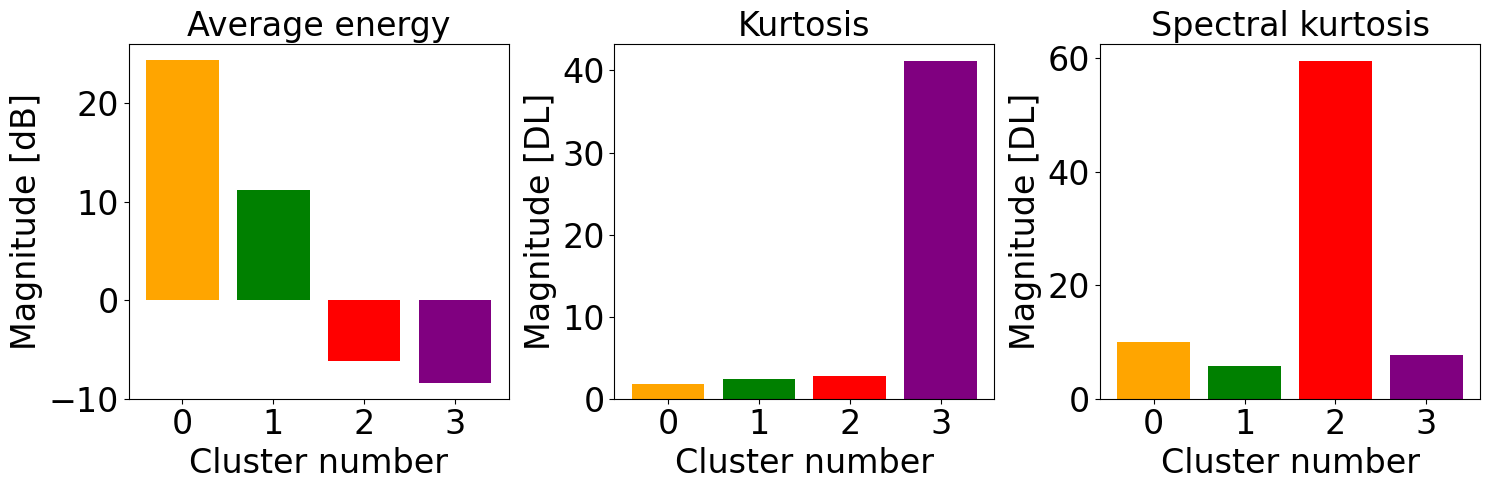

In [21]:
# Set clusters to None to plot all of them, otherwise, plot a list of int

fig = plot.plot_fft_by_group(
    tr_obj, labels_sorted, sampling_rate,
    clusters=None,
    xlims=[0,fft_lim*6/10],
    ylims=[-50,50],
    fundamental_freq=frequency,
    freq_threshold=freq_threshold,
    fig_height=Fig_Height,
    fig_width=Fig_Width,
    plot_full_reconstruction=False,
)

if savefigs_flag:
    save_figure(
        fig,
        f"FFT_reconstructions_{result_id}",
        fig_height=Fig_Height,
        fig_width=Fig_Width,
    )

fig = plot.plot_reconstructions_by_group(
    tr_obj, labels_sorted, t_plot, freq_threshold,
    fig_height=Fig_Height,
    fig_width=Fig_Width,
    xrange=(20, 41),
    # yrange=(-5, 15)
)

if savefigs_flag:
    save_figure(
        fig,
        f"WPT_reconstructions_{result_id}",
        fig_height=Fig_Height,
        fig_width=Fig_Width,
    )

fig = plot.plot_centers(
    classifying_metrics,
    centers_sorted,
)

if savefigs_flag:
    save_figure(
        fig,
        f"KMeans_Centers_{result_id}",
        fig_height=Fig_Height,
        fig_width=Fig_Width,
    )

In [22]:
centers_sorted

,index,average energy,kurtosis,spectral kurtosis
0,2,272.210884,1.762801,10.024655
1,3,13.140713,2.384067,5.786273
2,1,0.241269,2.758965,59.521170
3,0,0.145664,41.126294,7.707750


In [ ]:
from wavelet_transform.utils.extensions import psd

node = tr_obj.get_node(6, 1)
data = node.data
fft_data, freq_plot = psd(data, sampling_rate)
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=freq_plot / frequency,
        y=to_dB(np.abs(fft_data)),
        mode='lines',
        name='FFT of Node'
    )
)
fig.update_layout(
    title='PSD of WPT Node',
    xaxis_title='Frequency (Hz)',
    yaxis_title='Magnitude (dB)',
    # xaxis=dict(range=[0, fft_lim]),
    # yaxis=dict(range=[-100, 0])
)
fig.show()

inv_data = inv.inv_node(node)
fft_inv_data, freq_plot = psd(inv_data, sampling_rate)
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=freq_plot / frequency,
        y=to_dB(np.abs(fft_inv_data)),
        mode='lines',
        name='FFT of Inverse Node'
    )
)
fig.update_layout(
    title='FFT of Inverse WPT Node',
    xaxis_title='Frequency (Hz)',
    yaxis_title='Magnitude (dB)',
    xaxis=dict(range=[0, fft_lim]),
    # yaxis=dict(range=[-100, 0])
)
fig.show()

In [24]:
def trim(data, ratio):
    lim = int((1 - ratio) / 2 * len(data))
    if lim == 0:
        return data
    return data[lim:-lim]

# Add number to plot_centres to plot reconstructions of all nodes belonging to the cluster
# plot_centres = [i for i in range(5)]
plot_centres = np.arange(len(centers_sorted)) 
plot_centres = plot_centres[centers_sorted['kurtosis']>threshold]
reconstructions = [np.zeros(len(data_preprocessed)) for _ in range(2)]

for ii, (node, assignment) in enumerate(
    zip(tr_obj.get_leaf_nodes(freq_threshold=freq_threshold), labels_sorted)
):
    if int(assignment) in plot_centres:
        # List reconstructions
        rec_signal = inv.inv_node(node)

        j = 0 if sf.kurtosis(trim(rec_signal, inv_keep_ratio)) > threshold else 1  # shorten name for readability
        reconstructions[j] = reconstructions[j] + rec_signal
    else:
        rec_signal = inv.inv_node(node)
        reconstructions[1] += rec_signal


fig = go.Figure()
fig.add_trace(
    go.Scatter(
        y=reconstructions[0],
        mode="lines",
        name="higher than threshold",
    )
)
fig.add_trace(
    go.Scatter(
        y=reconstructions[1],
        mode="lines",
        name="lower than threshold",
    )
)
fig.show()


In [25]:
psd_rec_higher, freq_higher = psd(reconstructions[0], sampling_rate, frequency)
psd_rec_lower, freq_lower = psd(reconstructions[1], sampling_rate, frequency)

# Generate polynomial fitting of the PSD curve
psd_curve_db = ndi.gaussian_filter1d(to_dB(psd_rec_higher), 7)
psd_curve = 10 ** (psd_curve_db / 10)

rms = np.sqrt(np.mean(psd_curve**2))
half_peak = max(psd_curve) / 2
e_peak = max(psd_curve) / np.e**2

broadband_lines = {
    "rms": rms, 
    "FWHM": half_peak, 
    "1/e<sup>2</sup> peak": e_peak
}

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=freq_higher,
        y=to_dB(psd_rec_higher),
        mode="lines",
        name="higher than threshold",
    )
)
fig.add_trace(
    go.Scatter(
        x=freq_higher,
        y=psd_curve_db,
        name="envelope"
    )
)

for line_name, line in broadband_lines.items():
    db_line = 10 * np.log10(line)
    fig.add_trace(
        go.Scatter(
            x=freq_higher,
            y=db_line*np.ones(len(freq_higher)),
            line=dict(dash="dash"),
            name=line_name
        )
    )
fig.update_layout(
    xaxis=dict(title="f / f<sub>0</sub> [DL]", range=[0, 10]),
)

fig.show()

if savefigs_flag:
    save_figure(
        fig,
        f"Reconstruction_Broadband_{result_id}",
        fig_height=Fig_Height,
        fig_width=Fig_Width,
    )

In [26]:
print("Energy of the HIGH-kurtosis broadband [dB]: ",sf.avg_energy(trim(reconstructions[0], inv_keep_ratio))*std_original, 
      "\nEnergy of the LOW-kurtosis broadband [dB]:",sf.avg_energy(trim(reconstructions[1], inv_keep_ratio))*std_original)

Energy of the HIGH-kurtosis broadband [dB]:  9.850444688687566e-06 
Energy of the LOW-kurtosis broadband [dB]: 0.00419062689352976


In [27]:
print("Kurtosis of the HIGH-kurtosis broadband: ",sf.kurtosis(trim(reconstructions[0], inv_keep_ratio)), 
      "\nKurtosis of the LOW-kurtosis broadband:",sf.kurtosis(trim(reconstructions[1], inv_keep_ratio)))

Kurtosis of the HIGH-kurtosis broadband:  25.48499709214265 
Kurtosis of the LOW-kurtosis broadband: 1.8937855880616044


### Save results

In [28]:
additional_params = {
    "raw_data": data,
    "data_trim":data_trim,
    "data_preprocessed":data_preprocessed,
    "driving frequency": frequency,
    "centers_sorted":centers_sorted,
    "labels_sorted":labels_sorted,
    "psd_rec_thrsh_higher_freq":freq_higher,
    "psd_rec_thrsh_higher_mag":psd_rec_higher,
    "psd_rec_thrsh_lower_freq":freq_lower,
    "psd_rec_thrsh_lower_mag":psd_rec_lower,
}

if savedata_flag:
    results.save_data(
        result_id, data_train, tr_obj, centers, labels, 
        sampling_rate, freq_threshold, **additional_params
    )